# IngredientMassEstimation V5 — masa total auxiliar con MLP compartido

Experimento nuevo: **MLP compartido como V3 + cabezal auxiliar de masa total**.
Equivale a la ablación aux_only ya prevista, ahora con identidad V5 y resultados independientes.
No combina los MLP separados de V4 split_only. No promete mejora antes de medirla.

Mismos RGB, split provisional, vocabulario, cache de profundidad y presupuesto.
Todo entrenamiento/evaluación/test está desactivado al abrir. V3/V4 quedan en lectura.


## 1. Montar Drive

Usar la cuenta con acceso. Si está compartida, mantener el acceso directo en Mi unidad o adaptar DRIVE en punto 3.


In [1]:
from pathlib import Path
import os, sys, json, subprocess, shutil, zipfile, hashlib
from IPython.display import display
from google.colab import drive
drive.mount("/content/drive")


Mounted at /content/drive


## 2. Descargar la rama V5 publicada

Publicar v5-auxiliary-mass antes de clonar, o adaptar BRANCH. Repositorio privado: PRIVATE_REPO=True y secreto GITHUB_TOKEN.


In [2]:
URL = "https://github.com/marcogloazzo/IngredientMassEstimation.git"
BRANCH = "v5-auxiliary-mass"
PRIVATE_REPO = False
REPO = Path("/content/nutrition-code-v5")

def git_private(command):
    environment = os.environ.copy()
    try:
        if PRIVATE_REPO:
            from google.colab import userdata
            import base64
            token = userdata.get("GITHUB_TOKEN")
            authorization = base64.b64encode(f"x-access-token:{token}".encode()).decode()
            environment.update({
                "GIT_CONFIG_COUNT": "1", "GIT_CONFIG_KEY_0": "http.extraHeader",
                "GIT_CONFIG_VALUE_0": f"Authorization: Basic {authorization}",
            })
            del token, authorization
        result = subprocess.run(command, env=environment, capture_output=True, text=True)
        if result.returncode:
            raise RuntimeError("Git falló: revisá URL, rama publicada y permisos del token. No se imprime la credencial.")
        return result.stdout.strip()
    finally:
        environment.clear()

if (REPO / ".git").is_dir():
    current = git_private(["git", "-C", str(REPO), "branch", "--show-current"])
    assert current == BRANCH, f"Esta carpeta tiene otra rama: {current}. Usá una carpeta nueva."
    git_private(["git", "-C", str(REPO), "pull", "--ff-only", "origin", BRANCH])
else:
    git_private(["git", "clone", "--branch", BRANCH, "--single-branch", URL, str(REPO)])

PROJECT = next((p for p in (REPO, REPO / "IngredientMassEstimation")
                if (p / "config/query2label_100_v5.json").is_file()), None)
assert PROJECT is not None, "Falta publicar el código V5."
os.chdir(PROJECT)
print("Proyecto:", PROJECT)
print("Rama:", git_private(["git", "-C", str(REPO), "branch", "--show-current"]))

print("Commit:", git_private(["git", "-C", str(REPO), "rev-parse", "HEAD"]))



Proyecto: /content/nutrition-code-v5
Rama: v5-auxiliary-mass
Commit: d49690d54ce13c13a4ea8c546306f59c7b47f355


## 3. Dependencias y rutas V5

Configuración única, MLP compartido y auxiliar activo. No utilizar checkpoints V3/V4 como resume.


In [4]:
subprocess.run([sys.executable, "-m", "pip", "install", "-r", "requirements-v3.txt", "matplotlib"], check=True)
subprocess.run([sys.executable, "-m", "pip", "install", "-e", ".", "--no-deps"], check=True)
import torch

SOURCE = PROJECT / "src"

assert (SOURCE / "ingredient_mass").is_dir(), (
    "Falta el código del proyecto: revisá la sección 2."
)

sys.path.insert(0, str(SOURCE))

from ingredient_mass.notebook_reports import show_saved_report

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
DRIVE = Path("/content/drive/MyDrive/IngredientMassEstimation")
SOURCE_V3 = DRIVE / "v3"
SOURCE_V4 = DRIVE / "v4"
V5 = DRIVE / "v5"
EXPERIMENT_TAG = "run_01"
REPORT_TAG = "eval_01"
DIAGNOSTIC_TAG = "epoch39_01"
assert all("/" not in tag and "\\" not in tag and tag not in ("", ".", "..")
           for tag in (EXPERIMENT_TAG, REPORT_TAG, DIAGNOSTIC_TAG))
CONFIG = PROJECT / "config/query2label_100_v5.json"
cfg = json.loads(CONFIG.read_text())
assert cfg["split_task_mlps"] is False and cfg["auxiliary_total_mass"] is True
RUN = V5 / "runs" / f"query2label_100_v5_aux_{EXPERIMENT_TAG}"
VALIDATION = V5 / "reports" / f"{EXPERIMENT_TAG}_{REPORT_TAG}" / "validation"
TEST = VALIDATION.parent / "test"
CHECKPOINT = VALIDATION / "calibrated.pt"
V3_VALIDATION = SOURCE_V3 / "reports/run_01/validation"
V4_VALIDATION = SOURCE_V4 / "reports/split_only_run_01_eval_01/validation"
GATE_DIAGNOSTIC = V5 / "diagnostics" / f"v3_gate_{DIAGNOSTIC_TAG}"
LABELS_PARENT = Path("/content/v5_prepared")
PROCESSED = LABELS_PARENT / "processed_100_grouped_provisional"
DATA_PARENT = Path("/content/nutrition5k_v3")
DEPTH_CACHE = Path("/content/depth_v3_320")
DEPTH_ARCHIVE = SOURCE_V3 / "depth_v3_320.zip"

def run_stream(arguments):
    command = [str(arg) for arg in arguments]
    process = subprocess.Popen(command, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True, bufsize=1)
    try:
        for line in process.stdout:
            print(line, end="", flush=True)
        returncode = process.wait()
    except BaseException:
        process.terminate()
        process.wait()
        raise
    finally:
        process.stdout.close()
    if returncode:
        raise subprocess.CalledProcessError(returncode, command)

print("Device:", DEVICE, "| V5: MLP compartido + masa auxiliar")
print("RUN nuevo:", RUN)
print("Pesos nuevos:", {key: cfg["loss_weights"][key] for key in ("aux_mass", "mass_consistency")})
print("Fuentes históricas (solo lectura):", V3_VALIDATION, V4_VALIDATION)


Device: cuda | V5: MLP compartido + masa auxiliar
RUN nuevo: /content/drive/MyDrive/IngredientMassEstimation/v5/runs/query2label_100_v5_aux_run_01
Pesos nuevos: {'aux_mass': 0.25, 'mass_consistency': 0.1}
Fuentes históricas (solo lectura): /content/drive/MyDrive/IngredientMassEstimation/v3/reports/run_01/validation /content/drive/MyDrive/IngredientMassEstimation/v4/reports/split_only_run_01_eval_01/validation


## 4. Restaurar etiquetas agrupadas originales

Reutilizar el ZIP V3 y verificar sus hashes. No regenerar split ni vocabulario.


In [5]:
from pathlib import PurePosixPath
import stat

def extract_zip_safe(archive, destination):
    destination = Path(destination).resolve()
    destination.mkdir(parents=True, exist_ok=True)
    with zipfile.ZipFile(archive) as source:
        checked = []
        for info in source.infolist():
            name = info.filename.replace("\\", "/")
            relative = PurePosixPath(name)
            if relative.is_absolute() or not relative.parts or ":" in relative.parts[0]:
                raise ValueError(f"Nombre inseguro en ZIP: {name}")
            target = (destination / relative).resolve()
            if not target.is_relative_to(destination):
                raise ValueError(f"Ruta insegura en ZIP: {name}")
            if stat.S_ISLNK(info.external_attr >> 16):
                raise ValueError(f"No se aceptan enlaces en ZIP: {name}")
            checked.append((info, target, name.endswith("/")))
        for info, target, is_directory in checked:
            if is_directory:
                target.mkdir(parents=True, exist_ok=True)
            else:
                target.parent.mkdir(parents=True, exist_ok=True)
                with source.open(info) as incoming, target.open("wb") as outgoing:
                    shutil.copyfileobj(incoming, outgoing)


labels_zip = SOURCE_V3 / "data/processed_100_grouped_provisional.zip"
assert labels_zip.is_file(), f"Falta el paquete existente de V3: {labels_zip}"
if not (PROCESSED / "records.jsonl").is_file():
    extract_zip_safe(labels_zip, LABELS_PARENT)
package = json.loads((LABELS_PARENT / "package_manifest.json").read_text())
for name, digest in package["file_sha256"].items():
    path = PROCESSED / name
    assert path.is_file() and hashlib.sha256(path.read_bytes()).hexdigest() == digest, f"Etiquetas modificadas: {name}"
print("Etiquetas V3 conservadas:", PROCESSED)



Etiquetas V3 conservadas: /content/v5_prepared/processed_100_grouped_provisional


## 5. Diagnóstico de referencia V3 — opcional, sin modelo

RUN_GATE_DIAGNOSTIC=True solo para reproducir el diagnóstico. Ya fue analizado; V5 no exige repetirlo antes de entrenar. Se escribe en v5/diagnostics/ y se muestra con tablas nativas, sin HTML. Usar otro DIAGNOSTIC_TAG para repetir.


In [6]:
RUN_GATE_DIAGNOSTIC = False
if RUN_GATE_DIAGNOSTIC:
    assert (V3_VALIDATION / "predictions.npz").is_file(), "Falta predictions.npz de validación V3."
    run_stream([sys.executable, "-u", "scripts/diagnose_mass_gate.py",
                "--predictions", V3_VALIDATION / "predictions.npz",
                "--details", V3_VALIDATION / "evaluation_details.json",
                "--vocabulary", PROCESSED / "vocabulary.json",
                "--output-dir", GATE_DIAGNOSTIC])
figures = show_saved_report(GATE_DIAGNOSTIC / "diagnostic.json", "diagnostic",
                           "V3 · diagnóstico de referencia")
if not figures:
    print("Para generar el diagnóstico opcional: RUN_GATE_DIAGNOSTIC=True.")


Todavía no está disponible el reporte: /content/drive/MyDrive/IngredientMassEstimation/v5/diagnostics/v3_gate_epoch39_01/diagnostic.json
Para generar el diagnóstico opcional: RUN_GATE_DIAGNOSTIC=True.


## 6. Restaurar RGB y reutilizar depth V3

Misma geometría 320×320, sin regenerar depth. RUN_DATA_CHECK=True verifica datos/cache sin ejecutar modelo ni entrenar.


In [7]:
def dataset_roots():
    if not DATA_PARENT.is_dir():
        return []
    return sorted({folder.parent for folder in DATA_PARENT.rglob("metadata")
                   if folder.is_dir()
                   and (folder / "dish_metadata_cafe1.csv").is_file()
                   and (folder / "ingredients_metadata.csv").is_file()
                   and (folder.parent / "dish_ids").is_dir()
                   and (folder.parent / "imagery/realsense_overhead").is_dir()})

roots = dataset_roots()
if not roots:
    source = DRIVE / "nutrition5k_rgb.zip"
    assert source.is_file(), f"Falta: {source}"
    local = Path("/content/nutrition5k_rgb_v5.zip")
    shutil.copy2(source, local)
    extract_zip_safe(local, DATA_PARENT)
    roots = dataset_roots()
assert len(roots) == 1, f"Raíz RGB no única: {roots}"
DATA = roots[0]
if not (DEPTH_CACHE / "manifest.json").is_file():
    assert DEPTH_ARCHIVE.is_file(), "Falta el ZIP de mapas V3 320x320 en Drive."
    local = Path("/content/depth_v3_320.zip")
    shutil.copy2(DEPTH_ARCHIVE, local)
    extract_zip_safe(local, DEPTH_CACHE.parent)
assert (DEPTH_CACHE / "manifest.json").is_file(), "Revisá la estructura del ZIP de depth V3."
RUN_DATA_CHECK = False
if RUN_DATA_CHECK:
    run_stream([sys.executable, "-u", "scripts/train_image_model.py", "--config", CONFIG,
                "--dataset-root", DATA, "--processed-dir", PROCESSED, "--depth-cache", DEPTH_CACHE,
                "--device", DEVICE, "--check-data"])
print("RGB:", DATA, "| cache compatible:", DEPTH_CACHE)



RGB: /content/nutrition5k_v3/nutrition5k_dataset | cache compatible: /content/depth_v3_320


## 7. Entrenamiento V5 — desactivado

Solo habilitar cuando decidas entrenar. MODE="new" para la primera corrida.
Máximo 100 épocas y paciencia 8 por L1 de ingredientes, igual que V3/V4.
Auxiliar: supervisión de masa (0,25) y consistencia con suma de ingredientes (0,10), normalizadas por media train.
Gramos/nutrientes finales siguen usando p × c. Resume solo desde last.pt de esta V5.


In [8]:
RUN_TRAINING = True
MODE = "new"
TOTAL_EPOCHS = 100
if RUN_TRAINING:
    assert MODE in ("new", "resume")
    args = [sys.executable, "-u", "scripts/train_image_model.py", "--config", CONFIG,
            "--dataset-root", DATA, "--processed-dir", PROCESSED, "--depth-cache", DEPTH_CACHE,
            "--output-dir", RUN, "--torch-cache", DRIVE / "torch_cache",
            "--device", DEVICE, "--workers", "2", "--epochs", TOTAL_EPOCHS]
    if MODE == "resume":
        assert (RUN / "last.pt").is_file(), "Falta last.pt de esta V5."
        args += ["--resume", RUN / "last.pt"]
    else:
        assert not RUN.exists() or not any(RUN.iterdir()), "RUN tiene resultados: usar resume de V5 o un EXPERIMENT_TAG nuevo."
    run_stream(args)
else:
    print("Entrenamiento V5 desactivado.")


Device: cuda; presence loss: bce; classes: 100
Model: convnext_small_query2label_auxiliary_mass_v5; encoder adjustment: stages_2_4
Total-mass loss scale (training mean): 216.890021 g
Effective batch: 2 x 16; selection: ingredient_mass_l1_per_plate
Epoch 1: encoder stages_2_4 frozen (warmup)

Train 1: 100%|██████████| 1178/1178 [01:19<00:00, 14.88batch/s, loss=3.2546, samples=2355/2355]

Validation 1: 100%|██████████| 200/200 [00:06<00:00, 31.38batch/s, loss=3.1301, samples=400/400]
F1=0.161; ingredient L1/plate=313.3 g; mass MAE=101.6 g; calories MAE=133.4 kcal; epoch=86 s
Epoch 2: encoder stages_2_4 frozen (warmup)

Train 2: 100%|██████████| 1178/1178 [01:15<00:00, 15.59batch/s, loss=2.8768, samples=2355/2355]

Validation 2: 100%|██████████| 200/200 [00:06<00:00, 32.94batch/s, loss=2.8245, samples=400/400]
F1=0.289; ingredient L1/plate=285.0 g; mass MAE=90.4 g; calories MAE=109.7 kcal; epoch=82 s
Epoch 3: encoder stages_2_4 frozen (warmup)

Train 3: 100%|██████████| 1178/1178 [01:15<0

## 8. Validación, calibración y test — desactivados

Primero validación. Mantener RUN_TEST=False durante selección. Calibrar presencia no cambia gramos. Revisar MAE final de masa y nutrientes, además de L1 y métricas auxiliares.



Evaluating validation: 100%|██████████| 200/200 [00:06<00:00, 28.97batch/s, loss=2.0890, samples=400/400]
{
  "ingredient_recognition": {
    "micro_precision": 0.5957639939485628,
    "micro_recall": 0.6092202970297029,
    "micro_f1": 0.6024170108612513,
    "macro_f1": 0.4825849663524107,
    "exact_match": 0.17
  },
  "end_to_end_lightweight_mass": {
    "share_mae_percentage_points": 0.8290920257568359,
    "ingredient_mass_mae_present_grams": 16.325927734375,
    "ingredient_mass_l1_per_plate_grams": 173.63314819335938,
    "ingredient_mass_mae_all_classes_grams": 1.7363314628601074,
    "false_ingredient_mass_per_plate_grams": 41.71965408325195,
    "total_mass_mae_grams": 67.47321319580078,
    "total_mass_pmae": 0.3003982988062775,
    "nutrients": {
      "calories": {
        "mae": 92.25886535644531,
        "pmae": 0.3516665742270716
      },
      "fat": {
        "mae": 5.462130069732666,
        "pmae": 0.4074665677362696
      },
      "carbohydrates": {
        "mae"

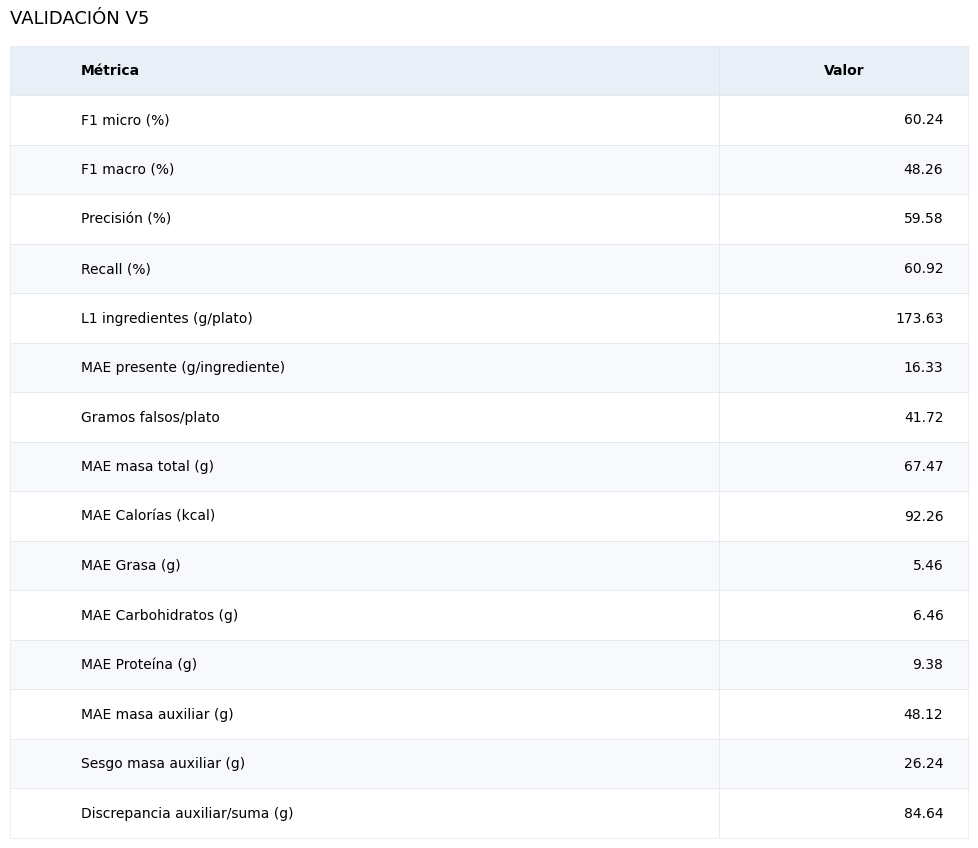

TEST V5 · solo referencia: época 23; umbral presencia 0.31.


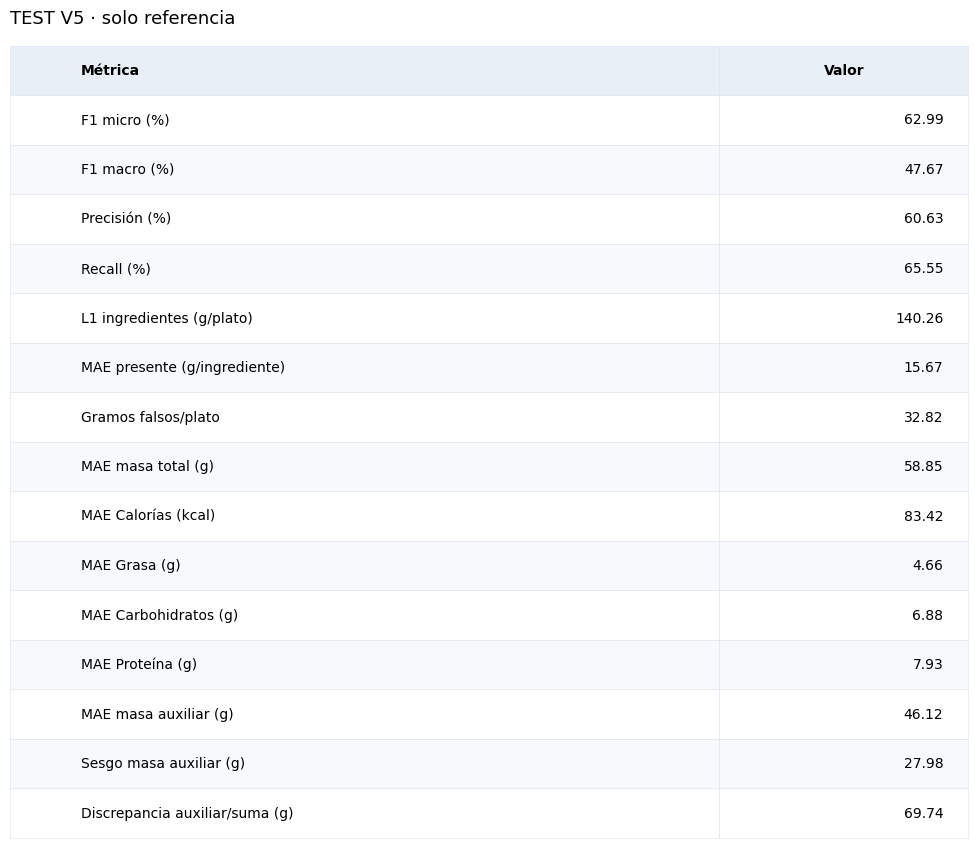

In [9]:
RUN_CALIBRATION = True
RUN_TEST = True
shared = ["--dataset-root", DATA, "--processed-dir", PROCESSED, "--depth-cache", DEPTH_CACHE,
          "--device", DEVICE, "--batch-size", "2", "--workers", "2"]
if RUN_CALIBRATION:
    assert (RUN / "best.pt").is_file(), "Falta best.pt de esta V5."
    run_stream([sys.executable, "-u", "scripts/evaluate_image_model.py", "--checkpoint", RUN / "best.pt",
                "--split", "validation", "--calibrate", "--output-dir", VALIDATION, *shared])
if RUN_TEST:
    assert CHECKPOINT.is_file(), "Primero calibrar con validación."
    run_stream([sys.executable, "-u", "scripts/evaluate_image_model.py", "--checkpoint", CHECKPOINT,
                "--split", "test", "--output-dir", TEST, *shared])
for split, folder in (("VALIDACIÓN V5", VALIDATION), ("TEST V5 · solo referencia", TEST)):
    figures = show_saved_report(folder / "metrics.json", "metrics", split)
if not RUN_CALIBRATION and not RUN_TEST:
    print("Evaluación desactivada: solo se muestran reportes ya guardados.")


## 9. Diagnóstico V5 y comparación con V3/V4 — tablas y gráficos

Mismos fingerprints y validación. Una mejora del cabezal auxiliar solo no demuestra mejora final; controlar composición, gramos falsos y nutrientes.


Validation epoch 23; samples=400; no model loaded.
baseline: L1=173.63 g/plate; false=41.72 g/plate; total MAE=67.47 g
oracle_remove_false_mass: L1=131.91 g/plate; false=0.00 g/plate; total MAE=98.36 g
oracle_presence_conditional: L1=121.00 g/plate; false=0.00 g/plate; total MAE=79.63 g
hard_product_report_threshold tau=0.310: L1=170.80 g/plate; false=37.54 g/plate; total MAE=71.36 g
hard_conditional_report_threshold tau=0.310: L1=181.98 g/plate; false=51.63 g/plate; total MAE=59.78 g
temperature_0.5: L1=173.97 g/plate; false=41.48 g/plate; total MAE=66.59 g
temperature_2: L1=177.67 g/plate; false=45.27 g/plate; total MAE=71.04 g
hard_product tau=0.850: L1=164.60 g/plate; false=17.81 g/plate; total MAE=102.33 g
hard_conditional tau=0.850: L1=165.65 g/plate; false=19.07 g/plate; total MAE=98.59 g
Reports: /content/drive/.shortcut-targets-by-id/1tQJYUpnMehp-_HEhiZaCaiYC_y4-u6BI/IngredientMassEstimation/v5/diagnostics/run_01_eval_01
V5 · diagnóstico de cantidad: validation, 400 imágenes, 

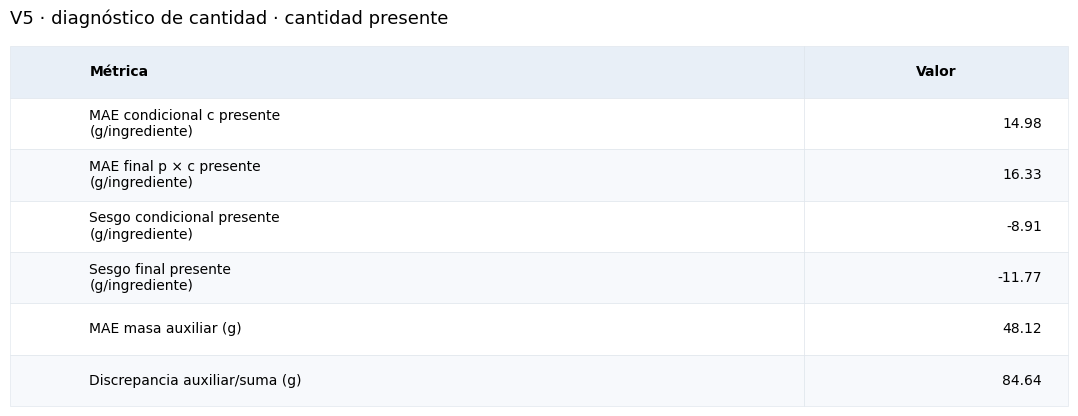

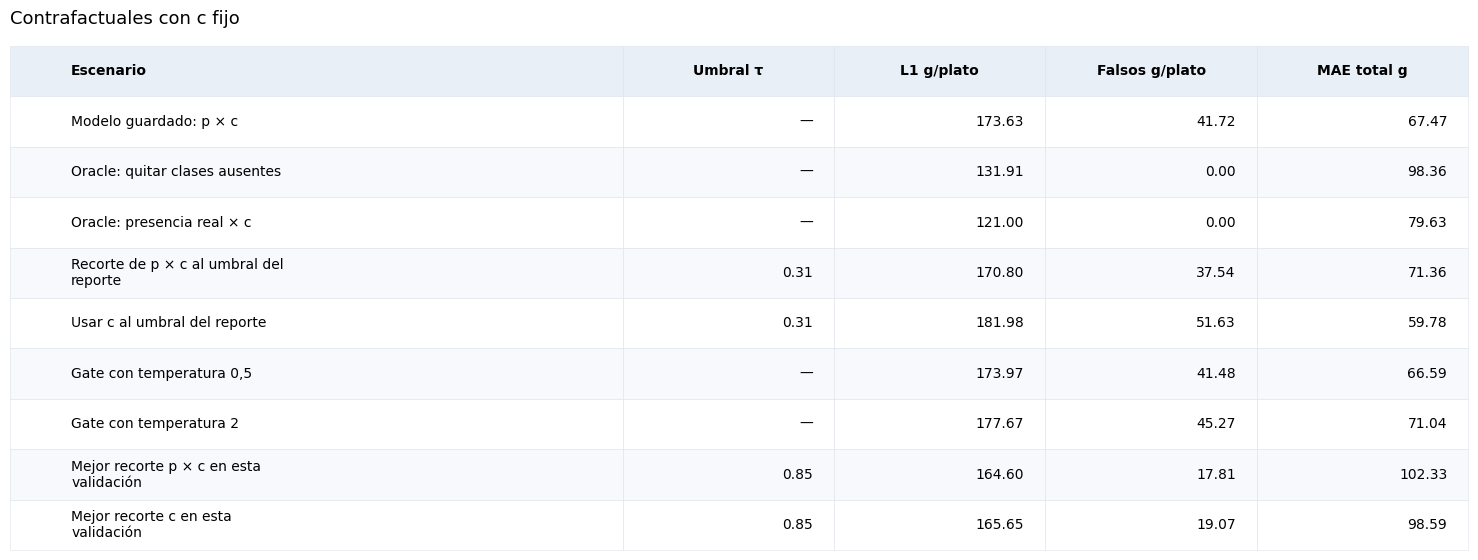

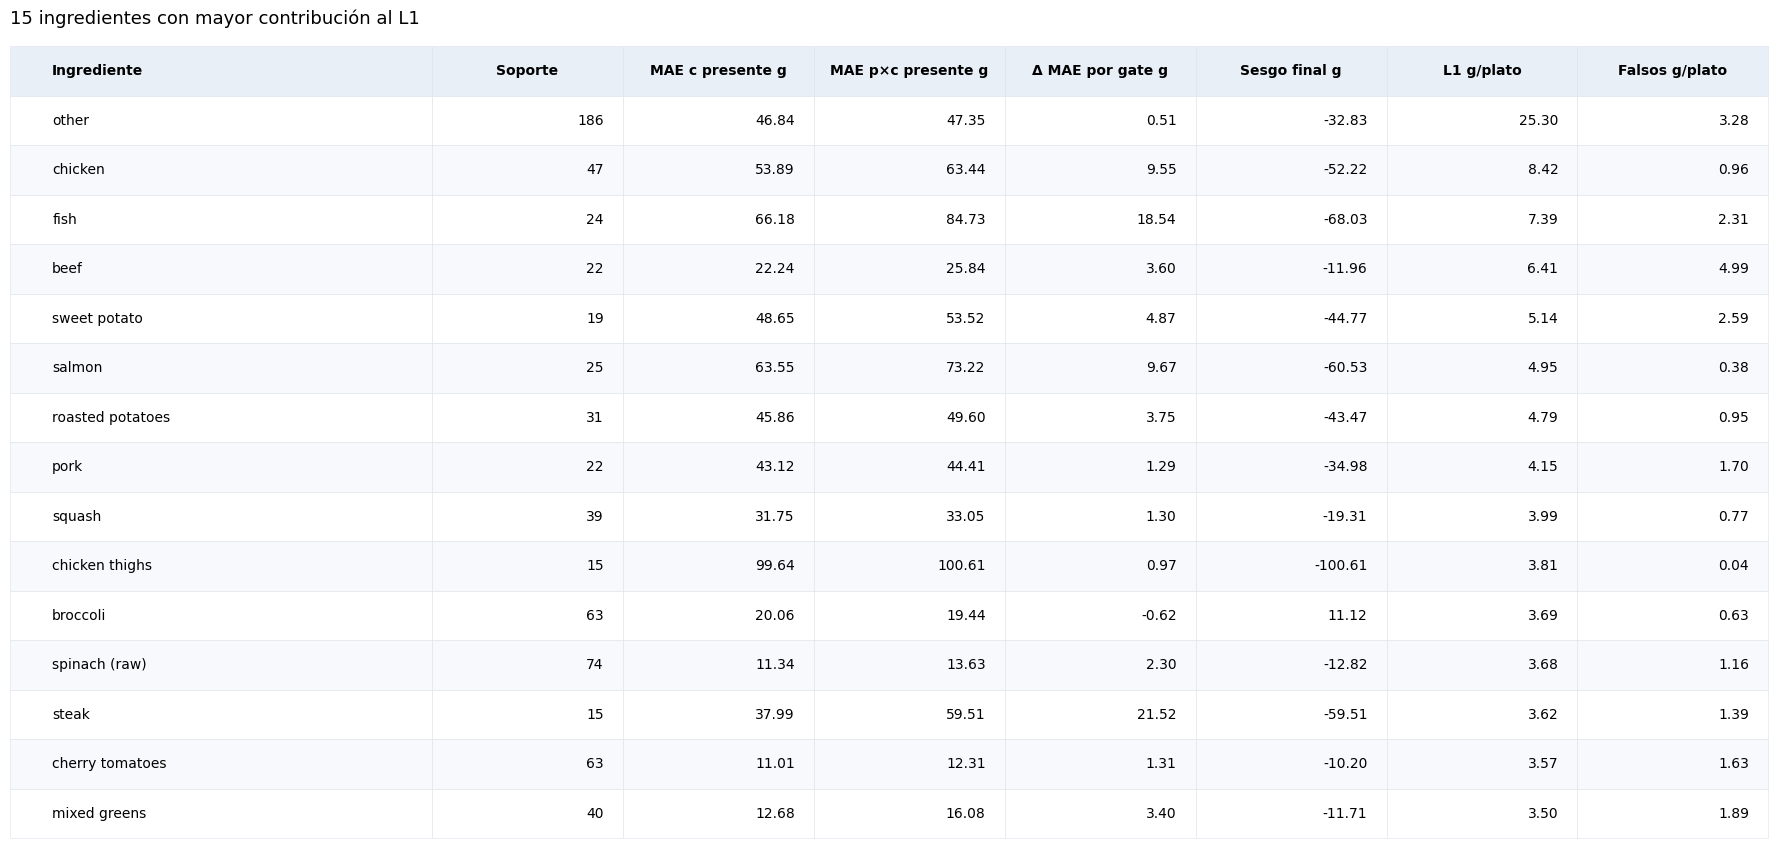

Δ MAE por gate positivo: p empeora el error con c fijo. Sesgo negativo: subestimación. Soporte bajo: promedio incierto.


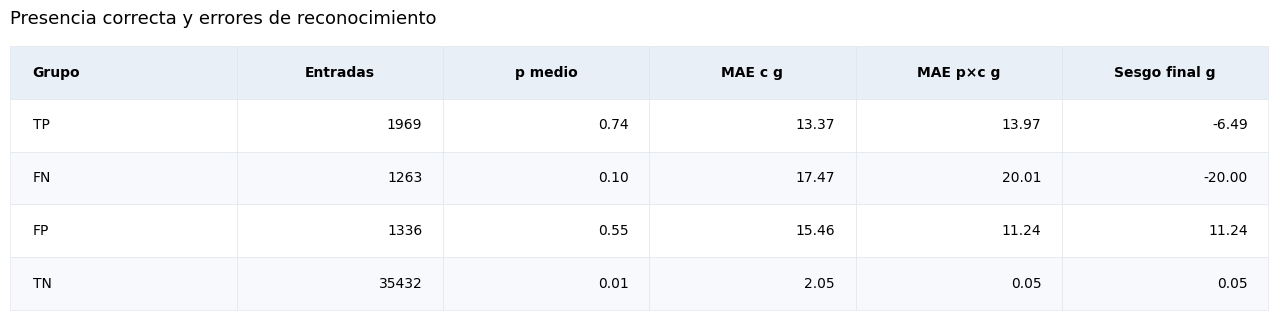

TP/FN son ingredientes reales; FP/TN son ausentes. MAE presente es por ingrediente, L1 se suma por plato.
{
  "controlled_data_comparison": true,
  "left": "/content/drive/MyDrive/IngredientMassEstimation/v3/reports/run_01/validation",
  "right": "/content/drive/MyDrive/IngredientMassEstimation/v5/reports/run_01_eval_01/validation",
  "details": [
    {
      "split": "validation",
      "samples": 400,
      "losses": {
        "total": 2.3123438065312802,
        "presence": 1.3411147581393015,
        "conditional": 0.04889646316718427,
        "false_mass": 0.12271395219775513,
        "ingredient_mass": 0.5342006539274007,
        "mass": 0.2865487103164196,
        "nutrition": 0.1609050338761881
      },
      "threshold": 0.3499999940395355,
      "epoch": 39,
      "model_type": "convnext_small_query2label_conditional_mass_v3",
      "prepared_fingerprint": {
        "records.jsonl": "01660407ca5159bce33276fbdf3ebcf7f439300cc3d39cf1656cd18bbe4b41d5",
        "vocabulary.json":

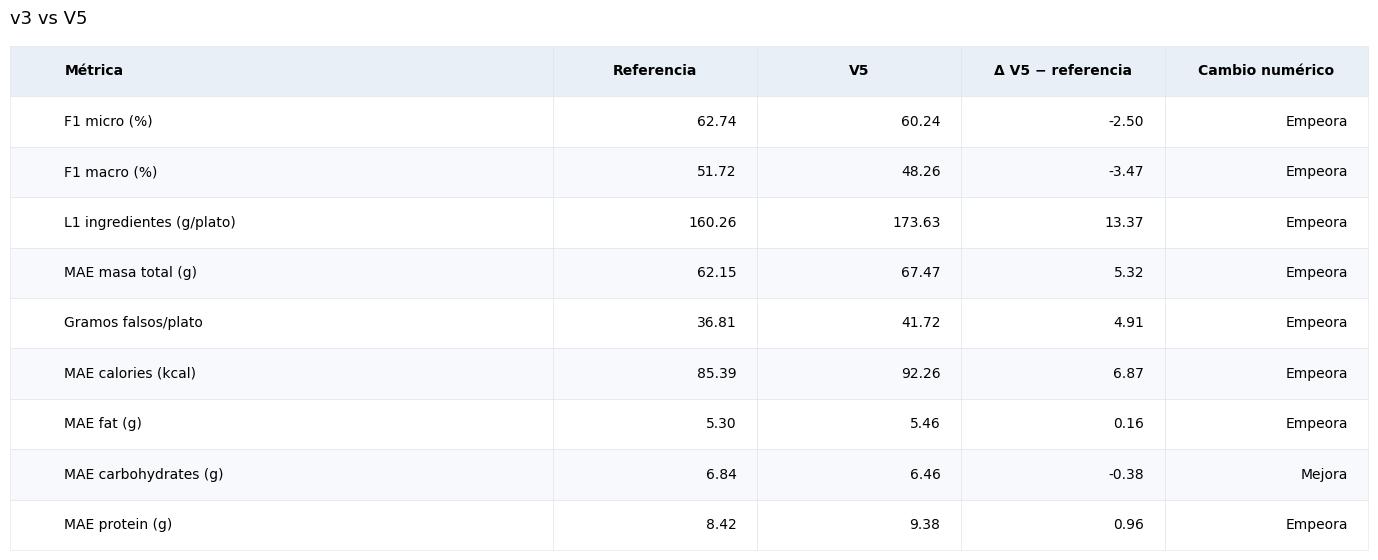

Para F1, Δ se expresa en puntos porcentuales. Mejora/empeora indica dirección numérica, no significancia estadística.


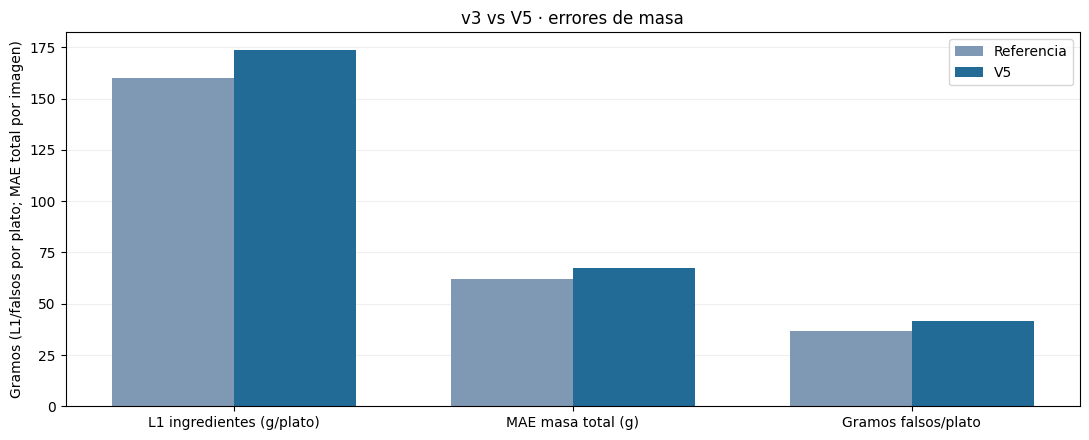

{
  "controlled_data_comparison": true,
  "left": "/content/drive/MyDrive/IngredientMassEstimation/v4/reports/split_only_run_01_eval_01/validation",
  "right": "/content/drive/MyDrive/IngredientMassEstimation/v5/reports/run_01_eval_01/validation",
  "details": [
    {
      "split": "validation",
      "samples": 400,
      "losses": {
        "total": 2.5443115517590194,
        "presence": 1.5526704263118154,
        "conditional": 0.0499688402254651,
        "false_mass": 0.11849420261165505,
        "ingredient_mass": 0.5271983253816143,
        "mass": 0.31304329410369974,
        "nutrition": 0.1687341853408725,
        "aux_mass": 0.0,
        "mass_consistency": 0.0
      },
      "threshold": 0.23499999940395355,
      "epoch": 48,
      "model_type": "convnext_small_query2label_specialized_mass_v4",
      "prepared_fingerprint": {
        "records.jsonl": "01660407ca5159bce33276fbdf3ebcf7f439300cc3d39cf1656cd18bbe4b41d5",
        "vocabulary.json": "61bcc0b71d4ec1deebdba2279f

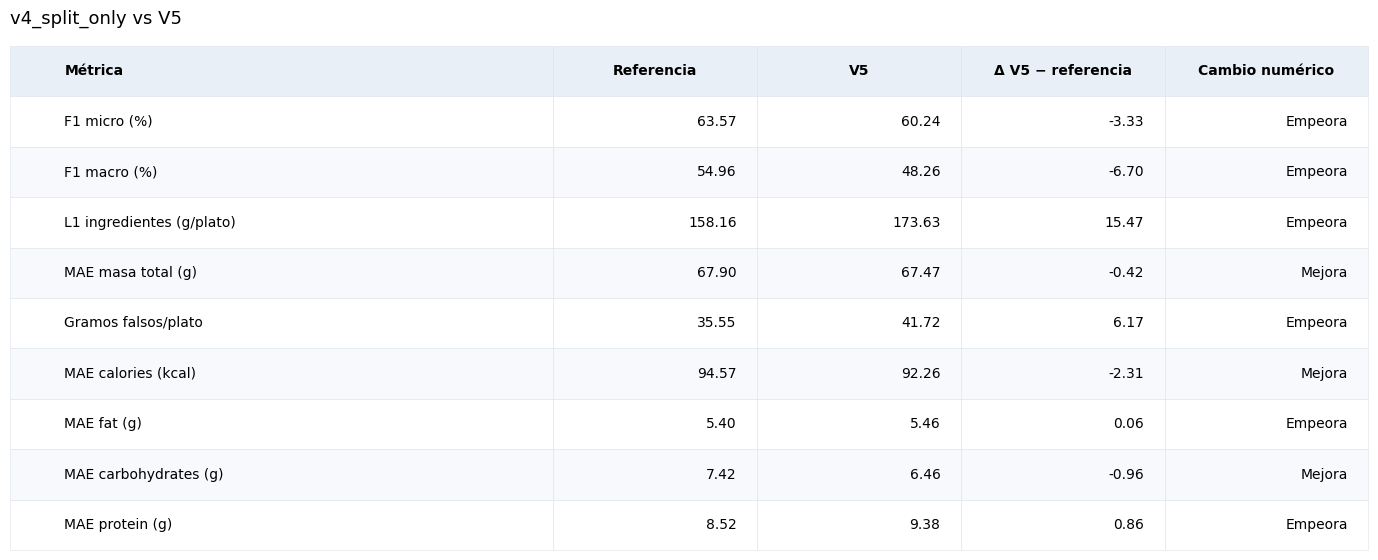

Para F1, Δ se expresa en puntos porcentuales. Mejora/empeora indica dirección numérica, no significancia estadística.


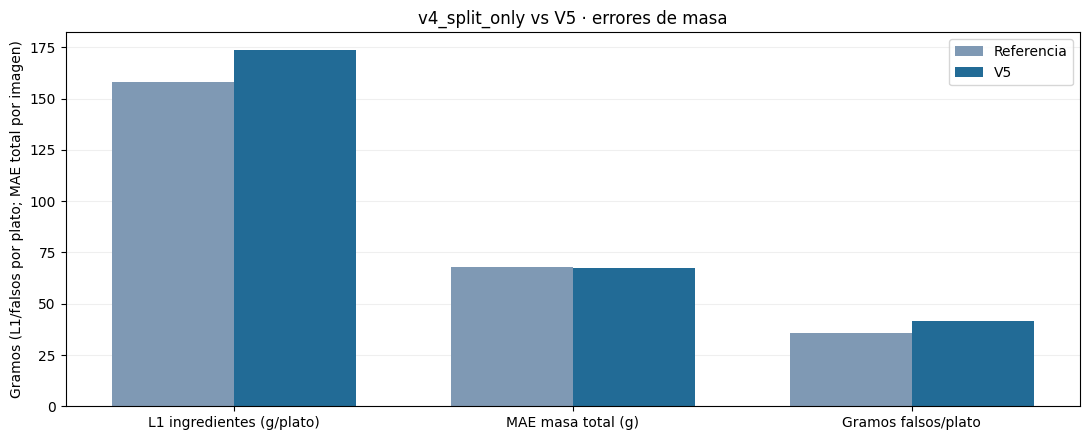

In [10]:
RUN_V5_DIAGNOSTIC = True
RUN_COMPARISON = True
V5_DIAGNOSTIC = V5 / "diagnostics" / f"{EXPERIMENT_TAG}_{REPORT_TAG}"
if RUN_V5_DIAGNOSTIC:
    run_stream([sys.executable, "-u", "scripts/diagnose_mass_gate.py",
                "--predictions", VALIDATION / "predictions.npz",
                "--details", VALIDATION / "evaluation_details.json",
                "--vocabulary", PROCESSED / "vocabulary.json", "--output-dir", V5_DIAGNOSTIC])
figures = show_saved_report(V5_DIAGNOSTIC / "diagnostic.json", "diagnostic", "V5 · diagnóstico de cantidad")
for label, previous in (("v3", V3_VALIDATION), ("v4_split_only", V4_VALIDATION)):
    comparison_dir = V5 / "comparisons" / f"{label}_vs_v5_{EXPERIMENT_TAG}_{REPORT_TAG}"
    if RUN_COMPARISON:
        assert (previous / "metrics.json").is_file(), f"Falta referencia: {previous}"
        run_stream([sys.executable, "-u", "scripts/compare_image_experiments.py",
                    "--left", previous, "--right", VALIDATION, "--output-dir", comparison_dir])
    figures = show_saved_report(comparison_dir / "comparison.json", "comparison", f"{label} vs V5")


## Git y Drive

Git: rama v5-auxiliary-mass, código compatible actualizado, config/query2label_100_v5.json, tests/test_v5.py, documentos V5, README y este notebook limpio.
No incluir notebooks V3/V4 ejecutados ni datos/checkpoints/reportes. No hubo commit/push automático.

Drive: abrir/guardar este notebook V5. Reutilizar nutrition5k_rgb.zip, v3/data/processed_100_grouped_provisional.zip y v3/depth_v3_320.zip.
Conservar v3/ y v4/ completas. Resultados nuevos en v5/. No subir nuevamente pesos ni generar mapas.

V5 parte de una corrida nueva desde ImageNet como los controles, no resume de V3/V4. No cambia a ASL ni agrega módulos de atención/encoder/depth.
